In [28]:
import sys
sys.path.append("..\..")
import importlib
import clean_data

importlib.reload(clean_data)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path 
from catboost import CatBoostClassifier, Pool 

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, log_loss, f1_score, balanced_accuracy_score, accuracy_score

from clean_data import feature_engineering_days

<>:2: SyntaxWarning: invalid escape sequence '\.'
<>:2: SyntaxWarning: invalid escape sequence '\.'
C:\Users\tprze\AppData\Local\Temp\ipykernel_13372\1210472872.py:2: SyntaxWarning: invalid escape sequence '\.'
  sys.path.append("..\..")


In [29]:
df = pd.read_csv("../../data/austin/raw/aac_intakes.csv")
outcomes = pd.read_csv("../../data/austin/raw/aac_intakes_outcomes.csv")

df["datetime"] = pd.to_datetime(df["datetime"])
outcomes["intake_datetime"] = pd.to_datetime(outcomes["intake_datetime"])

df = df.merge(
    outcomes[["animal_id_intake", "intake_datetime", "time_in_shelter_days"]],
    left_on=["animal_id", "datetime"],
    right_on=["animal_id_intake", "intake_datetime"],
    how="inner"
)

df = df[df["animal_type"] == "Dog"].copy()

In [30]:
df = feature_engineering_days(df)

df_dogs = df[df["animal_type"] == "Dog"].copy()
df_dogs = df_dogs.sort_values("intake_datetime").reset_index(drop=True)

bins = [-np.inf, 4, 10, np.inf]
df_dogs["target"] = pd.cut(
    df_dogs["time_in_shelter_days"], bins=bins, labels=[0, 1, 2]
).astype(int)

In [31]:
drop_cols = [
    "target", "time_in_shelter_days", "time_in_shelter", "intake_datetime", 
    "animal_type", "young_and_cat", "datetime"
]

X = df_dogs.drop(columns=drop_cols, errors="ignore")
y = df_dogs["target"]

#categorical features which will be available
cat_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
X[cat_features] = X[cat_features].fillna("Unknown").astype(str)

#70/15/15
n = len(X)
i1, i2 = int(n * 0.70), int(n * 0.85)

X_train, X_val, X_test = X.iloc[:i1], X.iloc[i1:i2], X.iloc[i2:]
y_train, y_val, y_test = y.iloc[:i1], y.iloc[i1:i2], y.iloc[i2:]

print("Split:", len(X_train), len(X_val), len(X_test))

Split: 31434 6736 6737


C:\Users\tprze\AppData\Local\Temp\ipykernel_13372\2754109917.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = X.select_dtypes(include=["object", "category"]).columns.tolist()


In [32]:
model = CatBoostClassifier(
    iterations=1200, learning_rate=0.03, depth=6,
    loss_function="MultiClass", random_seed=42, verbose=100
)

model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100,
    use_best_model=True
)

0:	learn: 1.0920264	test: 1.0915236	best: 1.0915236 (0)	total: 52.2ms	remaining: 1m 2s
100:	learn: 0.9248661	test: 0.9231623	best: 0.9231623 (100)	total: 5.62s	remaining: 1m 1s
200:	learn: 0.9002110	test: 0.9065176	best: 0.9065176 (200)	total: 11.2s	remaining: 55.6s
300:	learn: 0.8874788	test: 0.9007827	best: 0.9007827 (300)	total: 17.1s	remaining: 51s
400:	learn: 0.8766536	test: 0.8983404	best: 0.8982367 (397)	total: 22.9s	remaining: 45.7s
500:	learn: 0.8681073	test: 0.8969818	best: 0.8969818 (500)	total: 28.6s	remaining: 39.9s
600:	learn: 0.8617179	test: 0.8965648	best: 0.8965184 (540)	total: 34.4s	remaining: 34.3s
700:	learn: 0.8560330	test: 0.8960223	best: 0.8959720 (683)	total: 40s	remaining: 28.5s
800:	learn: 0.8505092	test: 0.8957813	best: 0.8957813 (800)	total: 45.6s	remaining: 22.7s
900:	learn: 0.8453322	test: 0.8956587	best: 0.8954561 (885)	total: 51.4s	remaining: 17.1s
1000:	learn: 0.8400365	test: 0.8949674	best: 0.8949561 (999)	total: 56.9s	remaining: 11.3s
1100:	learn: 0.8

CatBoostClassifier(depth=6, iterations=1200, learning_rate=0.03, loss_function='MultiClass', random_seed=42, verbose=100)

In [34]:
X_train.columns

Index(['breed', 'color', 'intake_condition', 'intake_type', 'name', 'sex',
       'intact', 'is_mixed_breed', 'primary_breed', 'is_mixed_color',
       'primary_color', 'has_name', 'name_length', 'age_days', 'day_of_week',
       'month', 'year', 'is_weekend'],
      dtype='str')

# Evaluation


In [35]:
probs = model.predict_proba(X_test)
y_pred = model.classes_[np.argmax(probs, axis=1)]

#Log Loss
ll = log_loss(y_test, probs, labels=model.classes_)

#Multiclass Brier Score
y_onehot = (
    np.asarray(y_test)[:, None]
    == np.asarray(model.classes_)[None, :]
).astype(int)

brier = np.mean(np.sum((probs - y_onehot) ** 2, axis=1))

#Macro F1
f1 = f1_score(y_test, y_pred, average="macro")

#Balanced Accuracy
bal_acc = balanced_accuracy_score(y_test, y_pred)

print(f"Log Loss:          {ll:.4f}")
print(f"Brier Score:       {brier:.4f}")
print(f"Macro F1:          {f1:.4f}")
print(f"Balanced Accuracy: {bal_acc:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred))

Log Loss:          0.8888
Brier Score:       0.5317
Macro F1:          0.5790
Balanced Accuracy: 0.5789

Classification report:
              precision    recall  f1-score   support

           0       0.64      0.57      0.60      2466
           1       0.59      0.64      0.61      2583
           2       0.52      0.52      0.52      1688

    accuracy                           0.59      6737
   macro avg       0.58      0.58      0.58      6737
weighted avg       0.59      0.59      0.59      6737



In [36]:
from sklearn.metrics import precision_recall_curve, average_precision_score

classes = list(model.classes_)
i2 = classes.index(2)

p2_val = model.predict_proba(X_val)[:, i2]
p2_test = model.predict_proba(X_test)[:, i2]

# Wybór progu na walidacji: najwyższa precyzja przy recall >= 0.6
prec, rec, thr = precision_recall_curve((y_val == 2).astype(int), p2_val)
ok = rec[:-1] >= 0.8
threshold = thr[ok][np.argmax(prec[:-1][ok])]
print(f"Próg dla klasy >10 dni: {threshold:.3f}")

# Ocena na teście
flag = p2_test >= threshold
y_long = (y_test == 2).astype(int)
tp = np.sum(flag & (y_long == 1))
print(f"Oznaczone: {flag.mean():.1%} zwierząt")
print(f"Precyzja: {tp / max(flag.sum(), 1):.3f}")
print(f"Recall:   {tp / y_long.sum():.3f}")
print(f"PR-AUC (klasa >10): {average_precision_score(y_long, p2_test):.3f}")

Próg dla klasy >10 dni: 0.231
Oznaczone: 49.3% zwierząt
Precyzja: 0.408
Recall:   0.803
PR-AUC (klasa >10): 0.530


In [37]:
def predict_dog(model, dog):
    probs = model.predict_proba(dog)[0]

    return pd.DataFrame({
        "Czas pobytu": ["≤4 dni", "4–10 dni", ">10 dni"],
        "Prawdopodobieństwo (%)": [
            round(probs[list(model.classes_).index(i)] * 100, 2)
            for i in [0, 1, 2]
        ]
    })


In [38]:
dog = X_test.iloc[[0]]
print(df_dogs.loc[dog.index[0], "time_in_shelter_days"])
display(predict_dog(model, dog))

1.16875


,Czas pobytu,Prawdopodobieństwo (%)
0,≤4 dni,16.20
1,4–10 dni,76.27
2,>10 dni,7.52


In [39]:
dog = X_test.iloc[[30]]

print(df_dogs.loc[dog.index[0], "time_in_shelter_days"])

display(predict_dog(model, dog))

0.1284722222222222


,Czas pobytu,Prawdopodobieństwo (%)
0,≤4 dni,36.93
1,4–10 dni,53.52
2,>10 dni,9.54


In [40]:
long_stay = X_test[df_dogs.loc[X_test.index, "time_in_shelter_days"] > 60]

dog = long_stay.iloc[[0]]

print(df_dogs.loc[dog.index[0], "time_in_shelter_days"])
display(predict_dog(model, dog))


64.74027777777778


,Czas pobytu,Prawdopodobieństwo (%)
0,≤4 dni,26.19
1,4–10 dni,32.07
2,>10 dni,41.73


In [19]:
# import shap

# explainer = shap.TreeExplainer(model)
# X_sample = X_test.sample(n=min(500, len(X_test)), random_state=42)
# shap_values = explainer(X_sample)

# print(shap_values.values.shape)

In [20]:
# class_idx = list(model.classes_).index(2)
# shap_long = shap_values[:, :, class_idx]
# shap.plots.beeswarm(shap_long, max_display=15)

In [21]:
# dog = X_test.iloc[[0]]
# display(predict_dog(model, dog))

# dog_shap = explainer(dog)

# shap.plots.waterfall(
#     dog_shap[0, :, class_idx],
#     max_display=15
# )

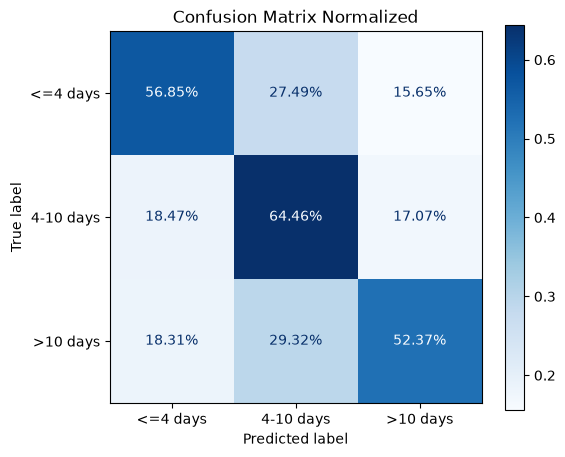

In [49]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_true=y_test,
    y_pred=y_pred,
    display_labels=["<=4 days", "4-10 days", ">10 days"],
    normalize="true",
    values_format=".2%",
    cmap="Blues",
    ax=ax,
)

ax.set_title("Confusion Matrix Normalized")
plt.grid(False)
plt.show()

In [ ]:
import pandas as pd
from sklearn.metrics import mean_absolute_error

df_old = pd.read_parquet("old_model_test_benchmark.parquet")

days = df_dogs.loc[X_train.index, "time_in_shelter_days"]

old_bins = pd.cut(days, bins=[-float("inf"), 7, 30, float("inf")], labels=[0, 1, 2])
old_medians = days.groupby(old_bins, observed=False).median().tolist()

new_bins = pd.cut(days, bins=[-float("inf"), 4, 10, float("inf")], labels=[0, 1, 2])
new_medians = days.groupby(new_bins, observed=False).median().tolist()

print(f"Stare mediany (reprezentanci klas): {[round(m, 2) for m in old_medians]}")
print(f"Nowe mediany (reprezentanci klas):  {[round(m, 2) for m in new_medians]}")

# Oczekiwana liczba dni
# Stary model
expected_old = (
    df_old["prob_class_0"] * old_medians[0] +
    df_old["prob_class_1"] * old_medians[1] +
    df_old["prob_class_2"] * old_medians[2]
)

# Nowy model
expected_new = (
    probs[:, 0] * new_medians[0] +
    probs[:, 1] * new_medians[1] +
    probs[:, 2] * new_medians[2]
)

# Błąd względem rzeczywistości
mae_old = mean_absolute_error(df_old["actual_days"], expected_old)
mae_new = mean_absolute_error(df_old["actual_days"], expected_new)

print(f"Średni błąd starego modelu: {mae_old:.2f} dni")
print(f"Średni błąd nowego modelu:  {mae_new:.2f} dni")

Stare mediany (reprezentanci klas): [3.23, 11.18, 59.08]
Nowe mediany (reprezentanci klas):  [1.14, 5.3, 24.07]
Średni błąd starego modelu: 9.88 dni
Średni błąd nowego modelu:  8.99 dni
